# Анализ результатов A/B-тестирования мобильного чекаута

**Контекст**: После релиза новой версии мобильного чекаута 1 апреля в исторических данных наблюдается снижение конверсии из корзины в оформление заказа.

**Задача**: Определить, связано ли снижение конверсии с изменением интерфейса мобильного чекаута, и оценить влияние новой версии на ключевые продуктовые и бизнес-метрики.

**Цель**: На основе исторических данных и результатов контролируемого A/B-тестирования оценить влияние редизайна на:
- Конверсию из корзины в оформление заказа.
- Среднюю выручку на одного участника эксперимента.

По результатам анализа сформулировать рекомендации по дальнейшему использованию новой версии чекаута.

In [72]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from scipy.stats import chi2_contingency

В эксперименте сравниваются две версии интерфейса:
- Группа A (контрольная) - старая версия чекаута.
- Группа B (тестовая) - новая версия чекаута.

Основная метрика - конверсия из корзины в оформление заказа (Cart-to-Checkout Conversion Rate).
Рассчитывается как отношение количества участников, достигших этапа checkout или purchase, к количеству участников, достигших этапа cart.

Нулевая гипотеза (H0): конверсия из корзины в оформление заказа одинакова в контрольной и тестовой группах.

Альтернативная гипотеза (H1): конверсия из корзины в оформление заказа различается между контрольной и тестовой группами.

## Проверка качества данных

Используются две таблицы:
- ab_test_checkout.csv - назначенный вариант, достигнутый этап и выручка;
- sessions.csv - история сессий с датой, устройством и достигнутым этапом.

In [90]:
base = "https://python-academy.org/static/product-analytics/dataset"
sessions = pd.read_csv(f"{base}/sessions.csv", parse_dates=["started_at"])
ab = pd.read_csv(f"{base}/ab_test_checkout.csv", parse_dates=["assigned_at"])
ab["chk"] = ab["reached_step"].isin(["checkout", "purchase"])
print(f"строк: {len(ab)}")

строк: 3000


In [91]:
ab.head()

,user_id,variant,assigned_at,reached_step,revenue_rub,chk
0,abu_00001,B,2026-06-13 03:53:03,purchase,104375,True
1,abu_00002,A,2026-06-11 18:01:14,checkout,0,True
2,abu_00003,A,2026-06-12 22:19:10,purchase,9464,True
3,abu_00004,B,2026-06-08 03:56:34,cart,0,False
4,abu_00005,B,2026-06-17 18:54:10,cart,0,False


In [92]:
# Размер таблиц
print("A/B-тест:")
print(f"Строк: {len(ab):,}")
print(f"Столбцов: {ab.shape[1]}")

print("\nИсторические данные:")
print(f"Строк: {len(sessions):,}")
print(f"Столбцов: {sessions.shape[1]}")

A/B-тест:
Строк: 3,000
Столбцов: 6

Исторические данные:
Строк: 68,668
Столбцов: 9


In [93]:
# Структура таблиц
print("\nСтолбцы ab:")
print(ab.dtypes)

print("\nСтолбцы sessions:")
print(sessions.dtypes)


Столбцы ab:
user_id                    str
variant                    str
assigned_at     datetime64[us]
reached_step               str
revenue_rub              int64
chk                       bool
dtype: object

Столбцы sessions:
session_id                 str
user_id                    str
started_at      datetime64[us]
duration_sec             int64
device                     str
source                     str
country                    str
pages_viewed             int64
reached_step               str
dtype: object


In [94]:
# Пропущенные значения
print("\nПропуски в ab:")
print(ab.isna().sum())

print("\nПропуски в sessions:")
print(sessions.isna().sum())


Пропуски в ab:
user_id         0
variant         0
assigned_at     0
reached_step    0
revenue_rub     0
chk             0
dtype: int64

Пропуски в sessions:
session_id         0
user_id            0
started_at         0
duration_sec       0
device             0
source             0
country         2078
pages_viewed       0
reached_step       0
dtype: int64


In [95]:
# Дубликаты строк
print("\nДубликаты:")
print(f"ab: {ab.duplicated().sum()}")
print(f"sessions: {sessions.duplicated().sum()}")


Дубликаты:
ab: 0
sessions: 0


In [96]:
# Распределение по группам
print("\nРаспределение вариантов:")
print(ab["variant"].value_counts(dropna=False))


Распределение вариантов:
variant
A    1517
B    1483
Name: count, dtype: int64


In [97]:
# Распределение по этапам
print("\nЭтапы в A/B-тесте:")
print(ab["reached_step"].value_counts(dropna=False))

print("\nЭтапы в исторических данных:")
print(sessions["reached_step"].value_counts(dropna=False))


Этапы в A/B-тесте:
reached_step
purchase    1389
cart        1225
checkout     386
Name: count, dtype: int64

Этапы в исторических данных:
reached_step
product     34122
home        19915
purchase     7327
cart         5416
checkout     1888
Name: count, dtype: int64


In [98]:
print("\nВыручка:")
print(ab["revenue_rub"].describe())


Выручка:
count      3000.000000
mean      15676.383000
std       30654.689525
min           0.000000
25%           0.000000
50%           0.000000
75%       19467.000000
max      250000.000000
Name: revenue_rub, dtype: float64


In [99]:
print(ab.columns.tolist())
print(sessions.columns.tolist())

['user_id', 'variant', 'assigned_at', 'reached_step', 'revenue_rub', 'chk']
['session_id', 'user_id', 'started_at', 'duration_sec', 'device', 'source', 'country', 'pages_viewed', 'reached_step']


**Вывод**: проблем с пропусками и полными дубликатами в A/B-тесте нет.

Уточнение: эксперимент запускался на этапе корзины.

In [100]:
# Проверка уникальности пользователей
print("Уникальность пользователей в A/B-тесте:")
print(f"Всего строк: {len(ab)}")
print(f"Уникальных пользователей: {ab['user_id'].nunique()}")
print(f"Повторяющихся записей пользователей: {ab['user_id'].duplicated().sum()}")

# Проверка, не попал ли один пользователь в обе группы
user_variants = ab.groupby("user_id")["variant"].nunique()

print("\nПользователи в нескольких вариантах:")
print((user_variants > 1).sum())

# Проверка согласованности chk и reached_step
check = ab["chk"] == ab["reached_step"].isin(["checkout", "purchase"])

print("\nПроверка метрики chk:")
print(f"Совпадений: {check.sum()}")
print(f"Несовпадений: {(~check).sum()}")

Уникальность пользователей в A/B-тесте:
Всего строк: 3000
Уникальных пользователей: 3000
Повторяющихся записей пользователей: 0

Пользователи в нескольких вариантах:
0

Проверка метрики chk:
Совпадений: 3000
Несовпадений: 0


In [101]:
print("\nВыручка по этапам:")
print(
    ab.groupby("reached_step")["revenue_rub"]
    .agg(["count", "mean", "median", "sum"])
    .round(0)
)


Выручка по этапам:
              count     mean   median       sum
reached_step                                   
cart           1225      0.0      0.0         0
checkout        386      0.0      0.0         0
purchase       1389  33858.0  21328.0  47029149


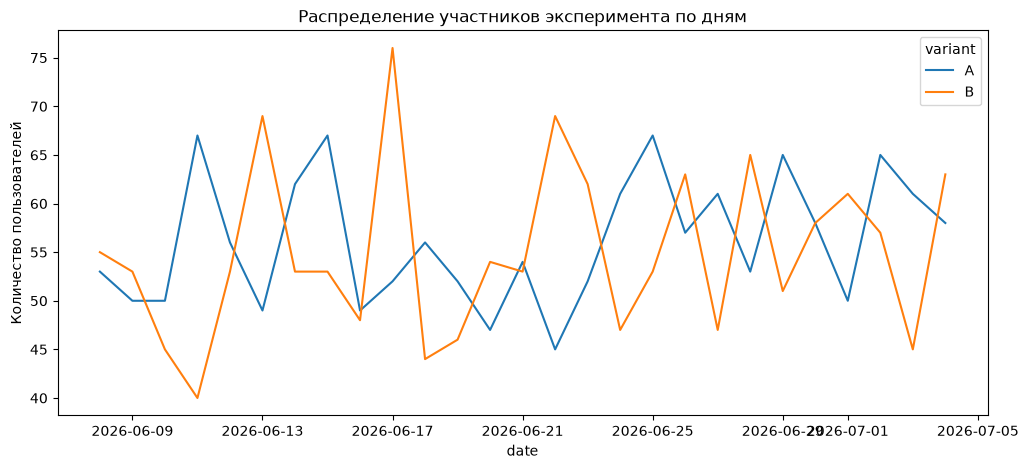

In [102]:
ab["date"] = ab["assigned_at"].dt.date

daily_users = (
    ab.groupby(["date", "variant"])["user_id"]
    .nunique()
    .unstack()
)

daily_users.plot(figsize=(12, 5))
plt.title("Распределение участников эксперимента по дням")
plt.ylabel("Количество пользователей")
plt.show()

**Вывод:** в таблице A/B-тестирования пропущенные значения и полные дубликаты не обнаружены. Идентификаторы пользователей уникальны: каждый участник присутствует только в одной экспериментальной группе.

В исторической таблице обнаружены пропуски в поле country (2078 записей). Поскольку страна не используется при расчёте основной метрики, эти пропуски не влияют на текущий анализ.

Эксперимент проводится на этапе корзины. Все участники включены в анализ в соответствии с назначенным вариантом.

## Проверка на перекос выборки (sample ratio mismatch, SRM)

*В рамках доступных данных проводится проверка SRM. Проверить баланс групп по пользовательским характеристикам невозможно, поскольку соответствующие признаки отсутствуют в экспериментальной таблице.*

*Проверка SRM проводится для оценки соответствия фактического распределения участников ожидаемому соотношению 50/50, предусмотренному дизайном эксперимента.*

In [103]:
variant_count = ab["variant"].value_counts()
variant_count

variant
A    1517
B    1483
Name: count, dtype: int64

In [104]:
# Фактическое количество пользователей в группах
observed = ab["variant"].value_counts().reindex(["A", "B"])

# Ожидаемое количество при распределении 50/50
expected = [len(ab) / 2, len(ab) / 2]

# Хи-квадрат
chi2, p_value = stats.chisquare(
    f_obs=observed.values,
    f_exp=expected
)

print(f"Группа A: {observed['A']} ({observed['A'] / len(ab) * 100:.2f}%)")
print(f"Группа B: {observed['B']} ({observed['B'] / len(ab) * 100:.2f}%)")
print(f"Ожидаемое количество в каждой группе: {expected[0]:.0f}")
print(f"Chi-square: {chi2:.4f}")
print(f"p-value: {p_value:.4f}")

if p_value < 0.05:
    print("Обнаружено статистически значимое отклонение от распределения 50/50.")
else:
    print("Статистически значимого отклонения от распределения 50/50 не обнаружено.")

Группа A: 1517 (50.57%)
Группа B: 1483 (49.43%)
Ожидаемое количество в каждой группе: 1500
Chi-square: 0.3853
p-value: 0.5348
Статистически значимого отклонения от распределения 50/50 не обнаружено.


**Вывод:** Статистически значимых отклонений от ожидаемого распределения 50/50 не обнаружено (χ² = 0,385; p = 0,535). Полученные результаты не указывают на наличие SRM.

## Конверсия *из корзины в оформление заказа*:

In [105]:
conversion = (
    ab.groupby("variant")
    .agg(
        users=("user_id", "nunique"),
        conversions=("chk", "sum"),
        conversion_rate=("chk", "mean")
    )
)

conversion["conversion_rate"] *= 100

print("Конверсия по группам:")
print(conversion.round(2))

diff = (
    conversion.loc["A", "conversion_rate"]
    - conversion.loc["B", "conversion_rate"]
)

print(f"\nРазница конверсий A - B: {diff:.2f} п.п.")

Конверсия по группам:
         users  conversions  conversion_rate
variant                                     
A         1517         1055            69.55
B         1483          720            48.55

Разница конверсий A - B: 20.99 п.п.


In [106]:
# Проверка статистической значимости разницы конверсий

table = pd.crosstab(ab["variant"], ab["chk"])

stat, p, dof, expected = chi2_contingency(table)

print("Таблица конверсий:")
print(table)

print(f"\nСтатистика chi-square: {stat:.2f}")
print(f"p-value: {p:.10f}")

if p < 0.05:
    print("Разница статистически значима.")
else:
    print("Статистически значимой разницы не обнаружено.")

Таблица конверсий:
chk      False  True 
variant              
A          462   1055
B          763    720

Статистика chi-square: 135.95
p-value: 0.0000000000
Разница статистически значима.


In [107]:
n_a = (ab["variant"] == "A").sum()
n_b = (ab["variant"] == "B").sum()

p_a = ab.loc[ab["variant"] == "A", "chk"].mean()
p_b = ab.loc[ab["variant"] == "B", "chk"].mean()

diff = p_a - p_b

se = np.sqrt(
    p_a * (1 - p_a) / n_a +
    p_b * (1 - p_b) / n_b
)

ci_low = (diff - 1.96 * se) * 100
ci_high = (diff + 1.96 * se) * 100

print(f"Разница конверсий: {diff * 100:.2f} п.п.")
print(f"95% доверительный интервал: [{ci_low:.2f}; {ci_high:.2f}] п.п.")

Разница конверсий: 20.99 п.п.
95% доверительный интервал: [17.55; 24.43] п.п.


**Вывод:** 
Вариант A показал конверсию 70% против 49% у варианта B. Разница составила 21 п.п. (95% ДИ: 17,55–24,43 п.п.). 

Различие статистически значимо (χ² = 135,95; p < 0,001).

Наблюдается существенное снижение конверсии после релиза новой версии мобильного чекаута.

## Выручка на участника эксперимента (Revenue per Participant)

In [108]:
# Средняя выручка на одного участника эксперимента
revenue = ab.groupby("variant").agg(
    users=("user_id", "nunique"),
    revenue_per_user=("revenue_rub", "mean"),
    total_revenue=("revenue_rub", "sum")
)

print(revenue.round(2))

diff_revenue = (
    revenue.loc["A", "revenue_per_user"]
    - revenue.loc["B", "revenue_per_user"]
)

print(f"\nРазница выручки на пользователя A - B: {diff_revenue:.2f} ₽")

         users  revenue_per_user  total_revenue
variant                                        
A         1517          18059.80       27396722
B         1483          13238.32       19632427

Разница выручки на пользователя A - B: 4821.48 ₽


### Перестановочный тест
Проверка, отличается ли средняя выручка между группами в любую сторону.

In [109]:
# Проверка значимости разницы выручки на пользователя

values = ab["revenue_rub"].to_numpy()
labels = (ab["variant"].to_numpy() == "A")

obs_diff = values[labels].mean() - values[~labels].mean()

n_perm = 20000
rng = np.random.default_rng(42)
extreme = 0

for _ in range(n_perm):
    shuffled = rng.permutation(labels)
    perm_diff = values[shuffled].mean() - values[~shuffled].mean()

    if abs(perm_diff) >= abs(obs_diff):
        extreme += 1

p_value = (extreme + 1) / (n_perm + 1)

print(f"Наблюдаемая разница: {obs_diff:.2f} ₽")
print(f"Экстремальных перестановок: {extreme} из {n_perm}")
print(f"p-value: {p_value:.6f}")

if p_value < 0.05:
    print("Разница статистически значима")
else:
    print("Статистически значимой разницы не обнаружено")

Наблюдаемая разница: 4821.48 ₽
Экстремальных перестановок: 0 из 20000
p-value: 0.000050
Разница статистически значима


In [110]:
# 95% доверительный интервал разницы выручки на пользователя

revenue_a = ab.loc[ab["variant"] == "A", "revenue_rub"].to_numpy()
revenue_b = ab.loc[ab["variant"] == "B", "revenue_rub"].to_numpy()

rng = np.random.default_rng(42)
n_boot = 10000
boot_diffs = []

for _ in range(n_boot):
    sample_a = rng.choice(revenue_a, size=len(revenue_a), replace=True)
    sample_b = rng.choice(revenue_b, size=len(revenue_b), replace=True)

    boot_diffs.append(sample_a.mean() - sample_b.mean())

ci_low, ci_high = np.percentile(boot_diffs, [2.5, 97.5])

print(f"Разница выручки на пользователя: {revenue_a.mean() - revenue_b.mean():.2f} ₽")
print(f"95% доверительный интервал: [{ci_low:.2f}; {ci_high:.2f}] ₽")

Разница выручки на пользователя: 4821.48 ₽
95% доверительный интервал: [2635.44; 6987.52] ₽


**Вывод:** Средняя выручка на одного участника эксперимента в контрольной группе A составила 18 059,80 ₽, в тестовой группе B — 13 238,32 ₽.

Разница между группами составила 4821,48 ₽ в пользу контрольной версии интерфейса.

95% доверительный интервал разницы составляет от 2635,44 до 6987,52 ₽. Перестановочный тест показал статистически значимое различие между группами (p = 0,00005).

Таким образом, использование новой версии чекаута сопровождается не только снижением конверсии, но и снижением средней выручки на участника эксперимента.

Сопоставление исторических данных и результатов эксперимента

In [111]:
mob = sessions[sessions["device"] == "mobile"]
carts = mob[mob["reached_step"].isin(["cart", "checkout", "purchase"])].copy()
carts["chk"] = carts["reached_step"].isin(["checkout", "purchase"])
post = carts["started_at"] >= "2026-04-01"
print(f"шаг корзина -> оформление: {carts[~post]['chk'].mean() * 100:.1f}% до релиза, {carts[post]['chk'].mean() * 100:.1f}% после")

ab["chk"] = ab["reached_step"].isin(["checkout", "purchase"])
exp = ab.groupby("variant")["chk"].mean() * 100
print(f"эксперимент: старая форма {exp['A']:.1f}%, новая {exp['B']:.1f}%")

rev = ab.groupby("variant")["revenue_rub"].mean()
print(f"Средняя выручка на участника эксперимента: +{rev['A'] - rev['B']:.0f} ₽ с корзины у старой формы")

шаг корзина -> оформление: 68.1% до релиза, 49.2% после
эксперимент: старая форма 69.5%, новая 48.6%
Средняя выручка на участника эксперимента: +4821 ₽ с корзины у старой формы


Средняя выручка на одного участника эксперимента в контрольной группе оказалась на 4821 ₽ выше, чем в тестовой. Это указывает на отрицательное влияние новой версии чекаута не только на конверсию, но и на выручку на участника эксперимента.

In [112]:
ab["chk"] = ab["reached_step"].isin(["checkout", "purchase"])

table = pd.crosstab(ab["variant"], ab["chk"])
stat, p, dof, expected = chi2_contingency(table)
print(f"p-value = {p:.6f}")

p-value = 0.000000


## Итоговый отчет 

**Что случилось**

После релиза новой версии мобильного чекаута 1 апреля наблюдается снижение конверсии из корзины в оформление заказа: с 68% до 49%.

**Результаты A/B-теста**

Контролируемый эксперимент на 3 000 участниках подтвердил наличие статистически значимых различий между версиями интерфейса.
- Конверсия контрольной группы A составила 69,55%.
- Конверсия тестовой группы B составила 48,55%.
- Разница — 20,99 п.п. в пользу контрольной группы.
- Средняя выручка на участника эксперимента оказалась выше в контрольной группе на 4 821 ₽.

Различия по обеим метрикам статистически значимы.

Результаты эксперимента согласуются с наблюдениями в исторических данных и указывают на негативный эффект новой версии мобильного чекаута.

**Рекомендация.**

Рекомендуется отказаться от текущей версии мобильного чекаута и восстановить предыдущую версию интерфейса.

Перед повторным запуском редизайна необходимо:

- Проанализировать пользовательский путь и выявить проблемные элементы интерфейса.
- Изучить записи пользовательских сессий.
- Проверить технические ошибки на этапе оформления.
- Провести новый A/B-тест после внесения изменений.

**Ограничение исследования.**

В рамках доступных данных не удалось проверить баланс экспериментальных групп по пользовательским характеристикам.

Также не установлены конкретные элементы редизайна, которые могли повлиять на снижение конверсии.

Историческое сравнение до и после релиза само по себе не доказывает причинно-следственную связь, поэтому основным источником оценки эффекта выступают результаты контролируемого эксперимента.

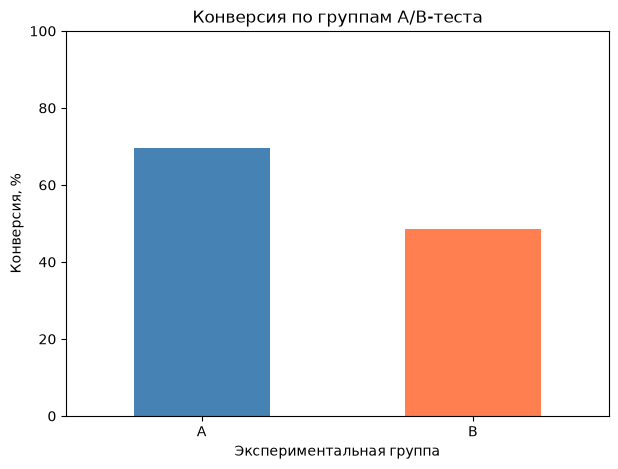

In [113]:
conversion["conversion_rate"].plot(
    kind="bar",
    figsize=(7, 5),
    color=["steelblue", "coral"]
)

plt.title("Конверсия по группам A/B-теста")
plt.xlabel("Экспериментальная группа")
plt.ylabel("Конверсия, %")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.show()

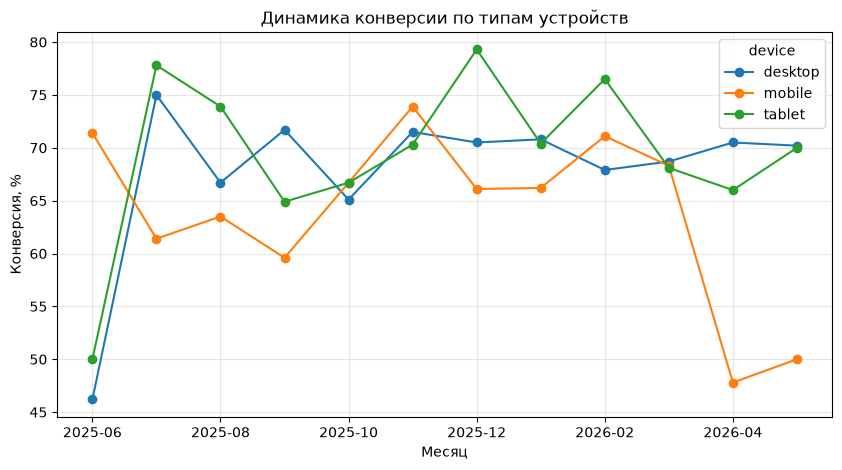

In [114]:
conv.plot(
    figsize=(10, 5),
    marker="o"
)

plt.title("Динамика конверсии по типам устройств")
plt.xlabel("Месяц")
plt.ylabel("Конверсия, %")
plt.xticks(rotation=0)
plt.grid(alpha=0.3)
plt.show()